# Step 1: Library Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn modules for preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier # For Feature Selection

# Models for Classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Display settings
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
pd.set_option('display.max_columns', None)

# Step 2: Loading dataset

In [ ]:
df = pd.read_csv('/content/predictive_maintenance.csv')

In [ ]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [ ]:
print(df['UDI'].unique())
print(df['Target'].unique())
print(df['Type'].unique())
print(df['Failure Type'].unique())


[    1     2     3 ...  9998  9999 10000]
[0 1]
['M' 'L' 'H']
['No Failure' 'Power Failure' 'Tool Wear Failure' 'Overstrain Failure'
 'Random Failures' 'Heat Dissipation Failure']


In [ ]:
df.drop(columns=['UDI', 'Target'], inplace=True)

In [ ]:
df.drop(columns=['Product ID'], inplace=True)

In [ ]:
df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure Type
0,M,298.1,308.6,1551,42.8,0,No Failure
1,L,298.2,308.7,1408,46.3,3,No Failure
2,L,298.1,308.5,1498,49.4,5,No Failure
3,L,298.2,308.6,1433,39.5,7,No Failure
4,L,298.2,308.7,1408,40.0,9,No Failure


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB


In [ ]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


In [ ]:
df.describe(exclude='number')

,Product ID,Type,Failure Type
count,10000,10000,10000
unique,10000,3,6
top,L57163,L,No Failure
freq,1,6000,9652


# Step 3: Data cleaning

In [ ]:
# 1. Remove duplicate rows
initial_shape = df.shape
df = df.drop_duplicates()
print(f"Dropped {initial_shape[0] - df.shape[0]} duplicate rows.")

Dropped 0 duplicate rows.


In [ ]:
# 2. Identify missing values
print("\n--- Missing Values Count ---")
print(df.isnull().sum())


--- Missing Values Count ---
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Failure Type               0
dtype: int64


In [ ]:
df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure Type,Temp_Difference_K,Power_Output_Proxy,Tool_Strain_Index
0,M,298.1,308.6,1551.0,42.8,0,No Failure,10.5,66382.8,0.0
1,L,298.2,308.7,1408.0,46.3,3,No Failure,10.5,65190.4,138.9
2,L,298.1,308.5,1498.0,49.4,5,No Failure,10.4,74001.2,247.0
3,L,298.2,308.6,1433.0,39.5,7,No Failure,10.4,56603.5,276.5
4,L,298.2,308.7,1408.0,40.0,9,No Failure,10.5,56320.0,360.0


# Step 4: Outliers detection & treatment

In [ ]:
def get_outlier_limits(dataframe, column, method='iqr'):
    """Calculates upper and lower limits based on the selected method."""
    if method == 'iqr':
        Q1 = dataframe[column].quantile(0.25)
        Q3 = dataframe[column].quantile(0.75)
        IQR = Q3 - Q1
        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR
    elif method == 'z-score':
        mean = dataframe[column].mean()
        std = dataframe[column].std()
        lower_limit = mean - 3 * std # 3 Standard Deviations
        upper_limit = mean + 3 * std
    elif method == 'percentile':
        lower_limit = dataframe[column].quantile(0.01) # 1st Percentile
        upper_limit = dataframe[column].quantile(0.99) # 99th Percentile
    else:
        raise ValueError("Method must be 'iqr', 'z-score', or 'percentile'")
    return lower_limit, upper_limit

def treat_outliers(dataframe, column, method='iqr', treatment='cap'):
    """Applies capping or trimming to the specified column."""
    df_treated = dataframe.copy()
    lower_limit, upper_limit = get_outlier_limits(df_treated, column, method)

    if treatment == 'cap':
        df_treated[column] = np.clip(df_treated[column], lower_limit, upper_limit)
    elif treatment == 'trim':
        df_treated = df_treated[(df_treated[column] >= lower_limit) & (df_treated[column] <= upper_limit)]
    else:
        raise ValueError("Treatment must be 'cap' or 'trim'")

    return df_treated

num_cols = df.select_dtypes(include=['float64', 'int64']).columns
sample_col = 'HeartDisease' if 'HeartDisease' in num_cols else num_cols[0]


In [ ]:
# ---------------------------------------------------------
# COMPARISON BLOCK: Testing all methods on a single column
# ---------------------------------------------------------
methods = ['iqr', 'z-score', 'percentile']
treatments = ['cap', 'trim']

print(f"--- Comparing Outlier Treatments for column: '{sample_col}' ---")
print(f"Original shape: {df.shape} | Original variance: {df[sample_col].var():.2f}\n")

for method in methods:
    for treatment in treatments:
        test_df = treat_outliers(df, sample_col, method=method, treatment=treatment)
        print(f"Method: {method.upper():<10} | Treatment: {treatment.upper():<4} | New Shape: {test_df.shape} | New Variance: {test_df[sample_col].var():.2f}")

--- Comparing Outlier Treatments for column: 'Air temperature [K]' ---
Original shape: (10000, 10) | Original variance: 4.00

Method: IQR        | Treatment: CAP  | New Shape: (10000, 10) | New Variance: 4.00
Method: IQR        | Treatment: TRIM | New Shape: (10000, 10) | New Variance: 4.00
Method: Z-SCORE    | Treatment: CAP  | New Shape: (10000, 10) | New Variance: 4.00
Method: Z-SCORE    | Treatment: TRIM | New Shape: (10000, 10) | New Variance: 4.00
Method: PERCENTILE | Treatment: CAP  | New Shape: (10000, 10) | New Variance: 3.97
Method: PERCENTILE | Treatment: TRIM | New Shape: (9838, 10) | New Variance: 3.76


In [ ]:
cols_for_outlier_summary = [col for col in num_cols if col != 'Student Age']

summary_rows = []

for col in cols_for_outlier_summary:
    for method in methods:
        lower_limit, upper_limit = get_outlier_limits(df, col, method=method)

        outliers_mask = (df[col] < lower_limit) | (df[col] > upper_limit)
        n_outliers = outliers_mask.sum()

        if n_outliers > 0:
            outlier_min = df.loc[outliers_mask, col].min()
            outlier_max = df.loc[outliers_mask, col].max()
            outlier_range = f"[{outlier_min:.2f}, {outlier_max:.2f}]"
        else:
            outlier_range = "No outliers"

        # Simulate actual capping to get the REAL resulting range (not just the raw limits)
        capped_col = np.clip(df[col], lower_limit, upper_limit)
        actual_capped_min = capped_col.min()
        actual_capped_max = capped_col.max()
        capped_range = f"[{actual_capped_min:.2f}, {actual_capped_max:.2f}]"

        summary_rows.append({
            "Column": col,
            "Method": method.upper(),
            "Outliers Detected": n_outliers,
            "Original Outlier Range": outlier_range,
            "Range After Capping (Actual)": capped_range
        })

outlier_summary_df = pd.DataFrame(summary_rows)

pd.set_option('display.max_rows', None)
display(outlier_summary_df)

,Column,Method,Outliers Detected,Original Outlier Range,Range After Capping (Actual)
0,Air temperature [K],IQR,0,No outliers,"[295.30, 304.50]"
1,Air temperature [K],Z-SCORE,0,No outliers,"[295.30, 304.50]"
2,Air temperature [K],PERCENTILE,162,"[295.30, 304.50]","[295.90, 304.10]"
3,Process temperature [K],IQR,0,No outliers,"[305.70, 313.80]"
4,Process temperature [K],Z-SCORE,0,No outliers,"[305.70, 313.80]"
5,Process temperature [K],PERCENTILE,195,"[305.70, 313.80]","[306.60, 313.20]"
6,Rotational speed [rpm],IQR,418,"[1896.00, 2076.63]","[1168.00, 1895.50]"
7,Rotational speed [rpm],Z-SCORE,204,"[2022.00, 2076.63]","[1168.00, 2021.58]"
8,Rotational speed [rpm],PERCENTILE,98,"[1168.00, 1274.00]","[1275.00, 2076.63]"
9,Torque [Nm],IQR,69,"[10.08, 69.89]","[12.80, 67.20]"


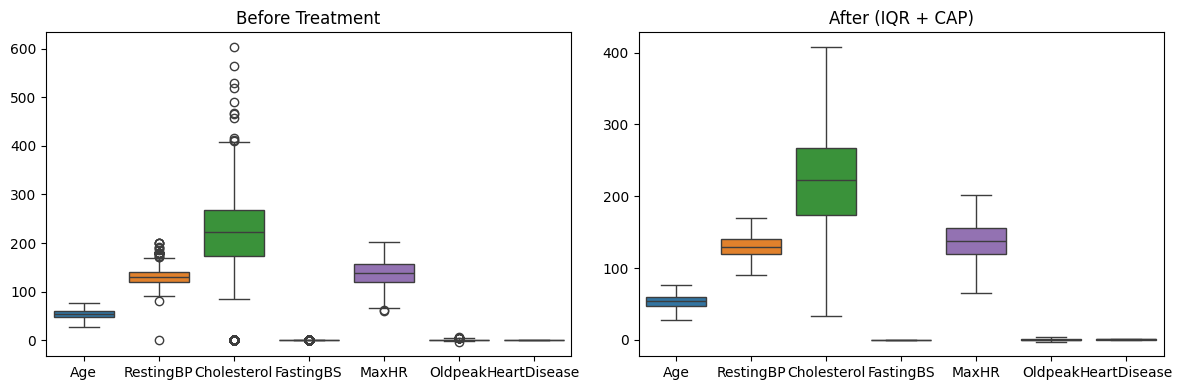


Applied IQR with CAPping to all numerical columns. Final shape: (918, 12)


In [ ]:
# ---------------------------------------------------------
# APPLYING CHOSEN STRATEGY TO ALL NUMERICAL COLUMNS
# ---------------------------------------------------------
# Set your preferred method based on the comparison above:
chosen_method = 'iqr'      # options: 'iqr', 'z-score', 'percentile'
chosen_treatment = 'cap'   # options: 'cap', 'trim'

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=df[num_cols])
plt.title("Before Treatment")

for col in num_cols:
    df = treat_outliers(df, col, method=chosen_method, treatment=chosen_treatment)

plt.subplot(1, 2, 2)
sns.boxplot(data=df[num_cols])
plt.title(f"After ({chosen_method.upper()} + {chosen_treatment.upper()})")
plt.tight_layout()
plt.show()

print(f"\nApplied {chosen_method.upper()} with {chosen_treatment.upper()}ping to all numerical columns. Final shape: {df.shape}")

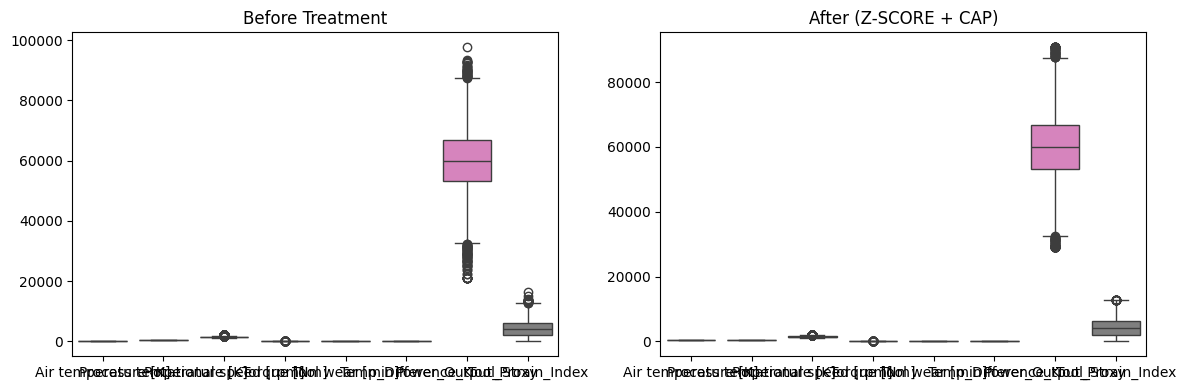


Applied Z-SCORE with CAPping to all numerical columns. Final shape: (10000, 10)


In [ ]:
# ---------------------------------------------------------
# APPLYING CHOSEN STRATEGY TO ALL NUMERICAL COLUMNS
# ---------------------------------------------------------
# Set your preferred method based on the comparison above:
chosen_method = 'z-score'      # options: 'iqr', 'z-score', 'percentile'
chosen_treatment = 'cap'   # options: 'cap', 'trim'

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=df[num_cols])
plt.title("Before Treatment")

for col in num_cols:
    df = treat_outliers(df, col, method=chosen_method, treatment=chosen_treatment)

plt.subplot(1, 2, 2)
sns.boxplot(data=df[num_cols])
plt.title(f"After ({chosen_method.upper()} + {chosen_treatment.upper()})")
plt.tight_layout()
plt.show()

print(f"\nApplied {chosen_method.upper()} with {chosen_treatment.upper()}ping to all numerical columns. Final shape: {df.shape}")

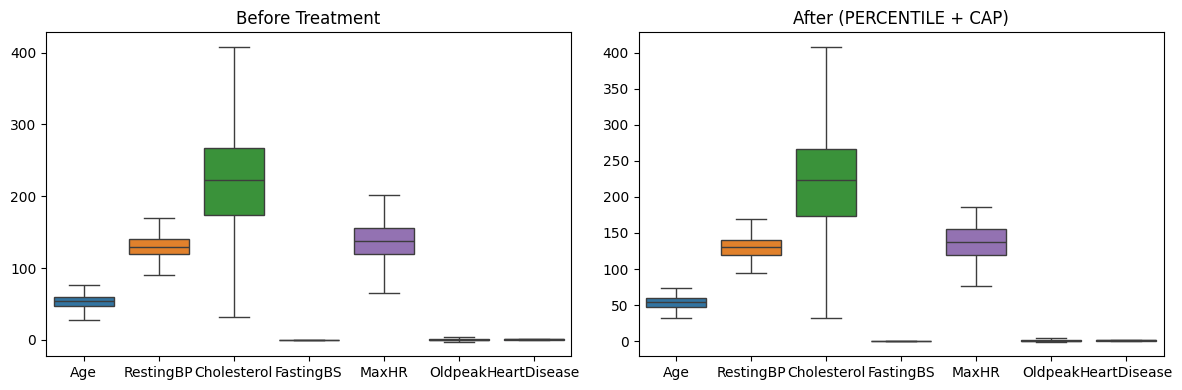


Applied PERCENTILE with CAPping to all numerical columns. Final shape: (918, 12)


In [ ]:
# ---------------------------------------------------------
# APPLYING CHOSEN STRATEGY TO ALL NUMERICAL COLUMNS
# ---------------------------------------------------------
# Set your preferred method based on the comparison above:
chosen_method = 'percentile'      # options: 'iqr', 'z-score', 'percentile'
chosen_treatment = 'cap'   # options: 'cap', 'trim'

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=df[num_cols])
plt.title("Before Treatment")

for col in num_cols:
    df = treat_outliers(df, col, method=chosen_method, treatment=chosen_treatment)

plt.subplot(1, 2, 2)
sns.boxplot(data=df[num_cols])
plt.title(f"After ({chosen_method.upper()} + {chosen_treatment.upper()})")
plt.tight_layout()
plt.show()

print(f"\nApplied {chosen_method.upper()} with {chosen_treatment.upper()}ping to all numerical columns. Final shape: {df.shape}")

# Step 5: Feature Engineering

In [ ]:
df['Temp_Difference_K'] = df['Process temperature [K]'] - df['Air temperature [K]']

df['Power_Output_Proxy'] = df['Rotational speed [rpm]'] * df['Torque [Nm]']

df['Tool_Strain_Index'] = df['Tool wear [min]'] * df['Torque [Nm]']

In [ ]:
df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure Type,Temp_Difference_K,Power_Output_Proxy,Tool_Strain_Index
0,M,298.1,308.6,1551.0,42.8,0,No Failure,10.5,66382.8,0.0
1,L,298.2,308.7,1408.0,46.3,3,No Failure,10.5,65190.4,138.9
2,L,298.1,308.5,1498.0,49.4,5,No Failure,10.4,74001.2,247.0
3,L,298.2,308.6,1433.0,39.5,7,No Failure,10.4,56603.5,276.5
4,L,298.2,308.7,1408.0,40.0,9,No Failure,10.5,56320.0,360.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Type                     10000 non-null  object 
 1   Air temperature [K]      10000 non-null  float64
 2   Process temperature [K]  10000 non-null  float64
 3   Rotational speed [rpm]   10000 non-null  float64
 4   Torque [Nm]              10000 non-null  float64
 5   Tool wear [min]          10000 non-null  int64  
 6   Failure Type             10000 non-null  object 
 7   Temp_Difference_K        10000 non-null  float64
 8   Power_Output_Proxy       10000 non-null  float64
 9   Tool_Strain_Index        10000 non-null  float64
dtypes: float64(7), int64(1), object(2)
memory usage: 781.4+ KB


In [ ]:
df['Failure Type'].unique()

array(['No Failure', 'Power Failure', 'Tool Wear Failure',
       'Overstrain Failure', 'Random Failures',
       'Heat Dissipation Failure'], dtype=object)

In [ ]:
df1 = pd.read_csv('/content/predictive_maintenance.csv')

In [ ]:
df['Failure'] = df1['Target']

In [ ]:
df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure Type,Temp_Difference_K,Power_Output_Proxy,Tool_Strain_Index,Failure
0,M,298.1,308.6,1551.0,42.8,0,No Failure,10.5,66382.8,0.0,0
1,L,298.2,308.7,1408.0,46.3,3,No Failure,10.5,65190.4,138.9,0
2,L,298.1,308.5,1498.0,49.4,5,No Failure,10.4,74001.2,247.0,0
3,L,298.2,308.6,1433.0,39.5,7,No Failure,10.4,56603.5,276.5,0
4,L,298.2,308.7,1408.0,40.0,9,No Failure,10.5,56320.0,360.0,0


# Step 6: Data Encoding

In [ ]:
# Identify target variable and categorical features
target_column1 = 'Failure'
target_column2 = 'Failure Type'

In [ ]:
size = {'L': 1, 'M': 2, 'H': 3}
df['Type'] = df['Type'].map(size)

In [ ]:
df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure Type,Temp_Difference_K,Power_Output_Proxy,Tool_Strain_Index,Failure
0,2,298.1,308.6,1551.0,42.8,0,No Failure,10.5,66382.8,0.0,0
1,1,298.2,308.7,1408.0,46.3,3,No Failure,10.5,65190.4,138.9,0
2,1,298.1,308.5,1498.0,49.4,5,No Failure,10.4,74001.2,247.0,0
3,1,298.2,308.6,1433.0,39.5,7,No Failure,10.4,56603.5,276.5,0
4,1,298.2,308.7,1408.0,40.0,9,No Failure,10.5,56320.0,360.0,0


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['Failure Type'] = le.fit_transform(df['Failure Type'])

print(dict(enumerate(le.classes_)))

{0: 'Heat Dissipation Failure', 1: 'No Failure', 2: 'Overstrain Failure', 3: 'Power Failure', 4: 'Random Failures', 5: 'Tool Wear Failure'}


In [ ]:
df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure Type,Temp_Difference_K,Power_Output_Proxy,Tool_Strain_Index,Failure
0,2,298.1,308.6,1551.0,42.8,0,1,10.5,66382.8,0.0,0
1,1,298.2,308.7,1408.0,46.3,3,1,10.5,65190.4,138.9,0
2,1,298.1,308.5,1498.0,49.4,5,1,10.4,74001.2,247.0,0
3,1,298.2,308.6,1433.0,39.5,7,1,10.4,56603.5,276.5,0
4,1,298.2,308.7,1408.0,40.0,9,1,10.5,56320.0,360.0,0


# Step 7: Data Splitting

In [ ]:
target_column = 'Failure' # REPLACE WITH YOUR TARGET COLUMN

In [ ]:
X = df.drop([target_column1, target_column2], axis=1)
Y = df[target_column1]

X_Train, X_Test, Y_Train, Y_Test = train_test_split(X, Y, test_size=0.2, random_state=0, stratify=Y)
print("Training Size: ", X_Train.shape)
print("Testing Size: ", X_Test.shape)

Training Size:  (8000, 9)
Testing Size:  (2000, 9)


# Step 8: Feature Scaling

In [ ]:
print("\nScaling numerical features...")
cols_to_scale = X_Train.select_dtypes(include=['float64', 'int64']).columns
scaler = StandardScaler()

# Fit on training data ONLY, then transform both
X_Train[cols_to_scale] = scaler.fit_transform(X_Train[cols_to_scale])
X_Test[cols_to_scale] = scaler.transform(X_Test[cols_to_scale])

display(X_Train.head())


Scaling numerical features...


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temp_Difference_K,Power_Output_Proxy,Tool_Strain_Index
8330,-0.748182,-0.601109,-0.208073,-0.172345,-0.108193,0.354069,0.891107,-0.129548,0.273740
1799,0.735570,-1.000530,-1.691299,-0.665365,0.507743,-0.208938,-0.502278,0.426218,-0.017654
7690,0.735570,0.247660,1.072895,0.282750,-0.360626,-1.632096,1.090162,-0.240893,-1.480276
3992,-0.748182,1.146356,0.870637,0.516618,-0.602962,0.322791,-0.999916,-0.488522,0.022777
1825,0.735570,-1.000530,-1.691299,1.591148,-1.239093,0.854520,-0.502278,-1.022647,0.069605


# Step 9: Feature Selection

Highly correlated features dropped: ['Process temperature [K]', 'Torque [Nm]', 'Power_Output_Proxy', 'Tool_Strain_Index']


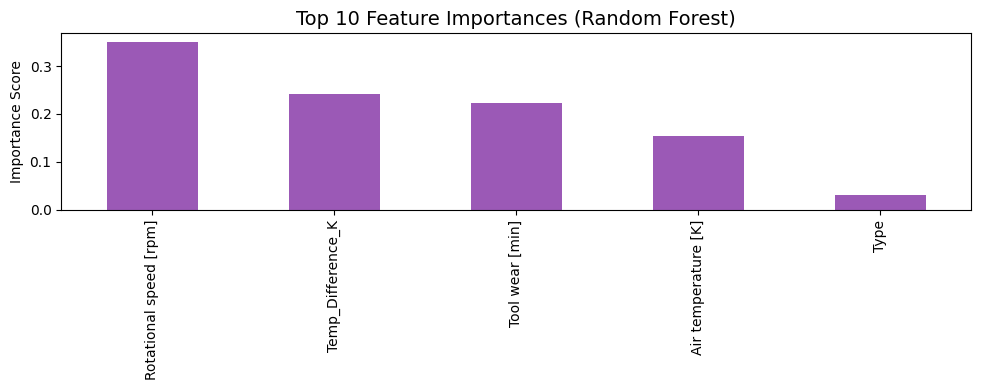

In [ ]:
# --- A. Filter Method: Correlation Matrix ---
corr_matrix = X_Train.corr()
threshold = 0.85
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column].abs() > threshold)]

print(f"Highly correlated features dropped: {to_drop}")
X_Train = X_Train.drop(columns=to_drop)
X_Test = X_Test.drop(columns=to_drop)

# --- B. Embedded Method: Random Forest Feature Importance ---
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_Train, Y_Train)

feature_importances = pd.Series(rf.feature_importances_, index=X_Train.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 4))
feature_importances.head(10).plot(kind='bar', color='#9b59b6')
plt.title("Top 10 Feature Importances (Random Forest)", fontsize=14)
plt.ylabel("Importance Score")
plt.tight_layout()
plt.show()

# Step 10: Classification Model Comparison


✅ Data Preprocessing Complete! Training Classification Models...

K-Nearest Neighbors Accuracy: 0.9705
Decision Tree Accuracy: 0.9600
Random Forest Accuracy: 0.9725
Support Vector Machine Accuracy: 0.9680


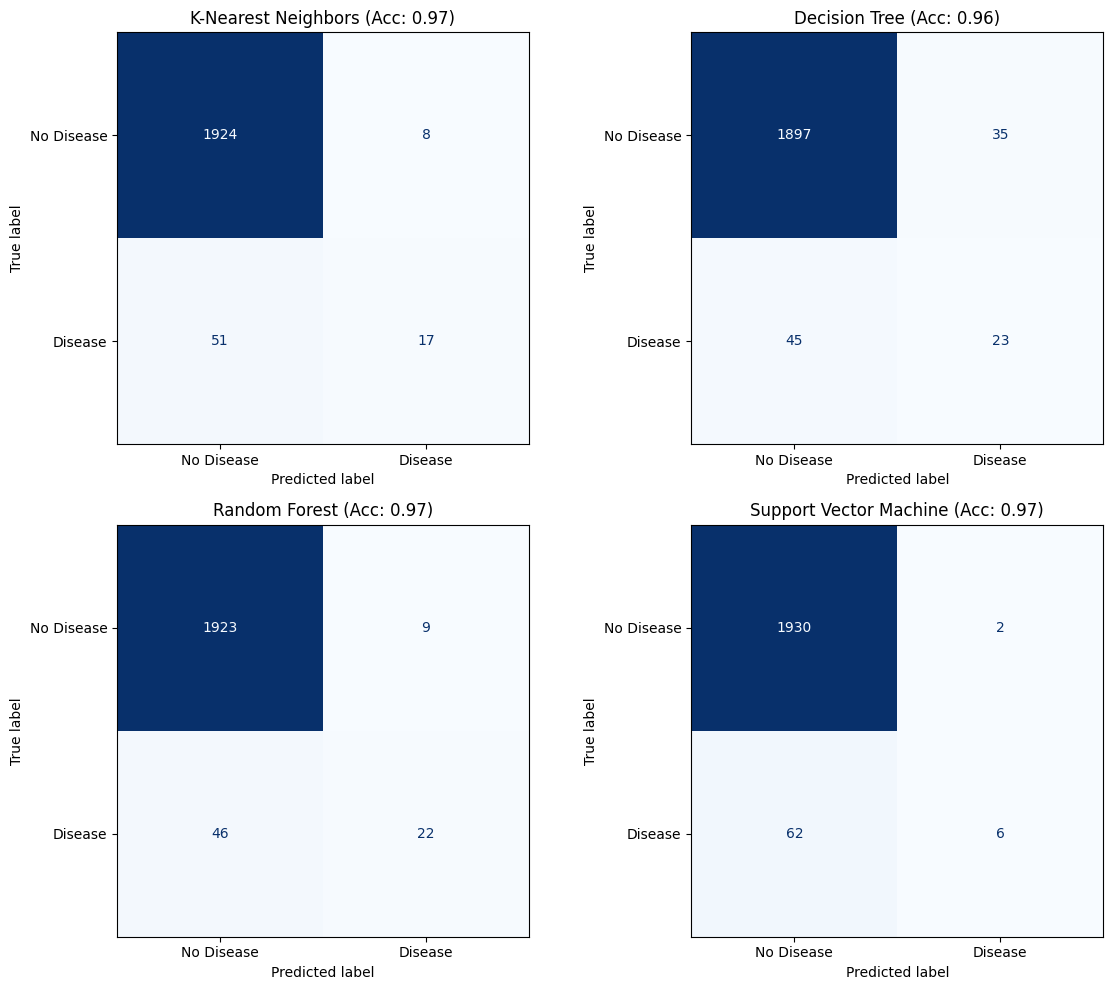

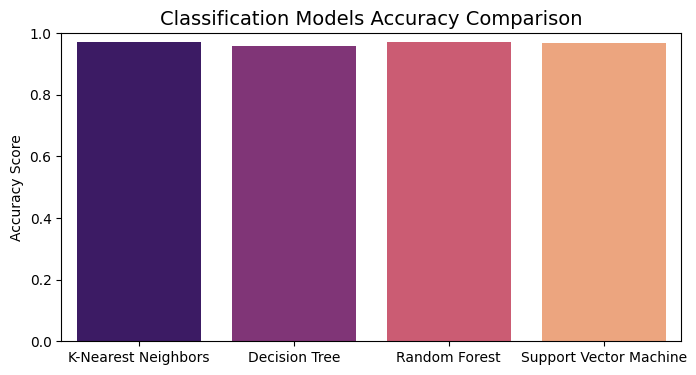

In [ ]:
print("\n✅ Data Preprocessing Complete! Training Classification Models...\n")

# Initialize models
models = {
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Support Vector Machine": SVC(random_state=42)
}

# Dictionary to store accuracy scores
accuracy_results = {}

# Train, predict, and evaluate each model
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models.items()):
    # Train
    model.fit(X_Train, Y_Train)
    # Predict
    y_pred = model.predict(X_Test)
    # Calculate Accuracy
    acc = accuracy_score(Y_Test, y_pred)
    accuracy_results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")

    # Plot Confusion Matrix
    cm = confusion_matrix(Y_Test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Disease', 'Disease'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f"{name} (Acc: {acc:.2f})")

plt.tight_layout()
plt.show()

# Plot Model Comparison
plt.figure(figsize=(8, 4))
sns.barplot(x=list(accuracy_results.keys()), y=list(accuracy_results.values()), palette='magma')
plt.title("Classification Models Accuracy Comparison", fontsize=14)
plt.ylabel("Accuracy Score")
plt.ylim(0, 1)
plt.show()

#No feature selection

In [ ]:
X = df.drop([target_column1, target_column2], axis=1)
Y = df[target_column1]

X_Train, X_Test, Y_Train, Y_Test = train_test_split(X, Y, test_size=0.2, random_state=0, stratify=Y)
print("Training Size: ", X_Train.shape)
print("Testing Size: ", X_Test.shape)

Training Size:  (8000, 9)
Testing Size:  (2000, 9)


In [ ]:
print("\nScaling numerical features...")
cols_to_scale = X_Train.select_dtypes(include=['float64', 'int64']).columns
scaler = StandardScaler()

# Fit on training data ONLY, then transform both
X_Train[cols_to_scale] = scaler.fit_transform(X_Train[cols_to_scale])
X_Test[cols_to_scale] = scaler.transform(X_Test[cols_to_scale])

display(X_Train.head())


Scaling numerical features...


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temp_Difference_K,Power_Output_Proxy,Tool_Strain_Index
8330,-0.748182,-0.601109,-0.208073,-0.172345,-0.108193,0.354069,0.891107,-0.129548,0.273740
1799,0.735570,-1.000530,-1.691299,-0.665365,0.507743,-0.208938,-0.502278,0.426218,-0.017654
7690,0.735570,0.247660,1.072895,0.282750,-0.360626,-1.632096,1.090162,-0.240893,-1.480276
3992,-0.748182,1.146356,0.870637,0.516618,-0.602962,0.322791,-0.999916,-0.488522,0.022777
1825,0.735570,-1.000530,-1.691299,1.591148,-1.239093,0.854520,-0.502278,-1.022647,0.069605


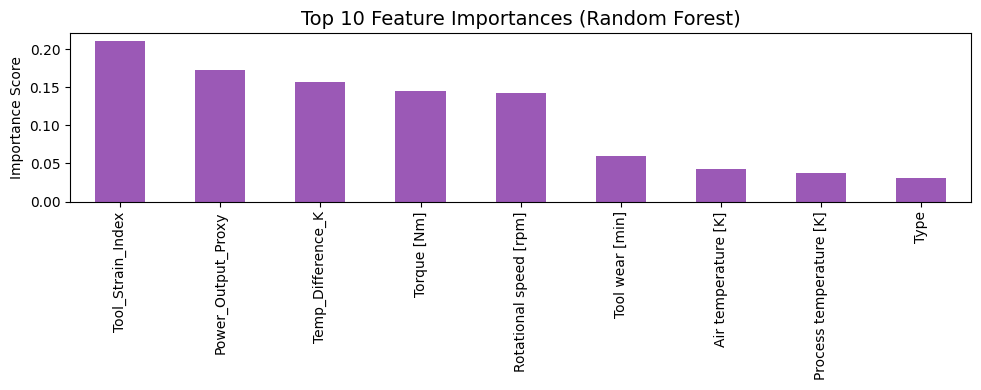

In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_Train, Y_Train)

feature_importances = pd.Series(rf.feature_importances_, index=X_Train.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 4))
feature_importances.head(10).plot(kind='bar', color='#9b59b6')
plt.title("Top 10 Feature Importances (Random Forest)", fontsize=14)
plt.ylabel("Importance Score")
plt.tight_layout()
plt.show()


✅ Data Preprocessing Complete! Training Classification Models...

K-Nearest Neighbors Accuracy: 0.9720
Decision Tree Accuracy: 0.9845
Random Forest Accuracy: 0.9910
Support Vector Machine Accuracy: 0.9775


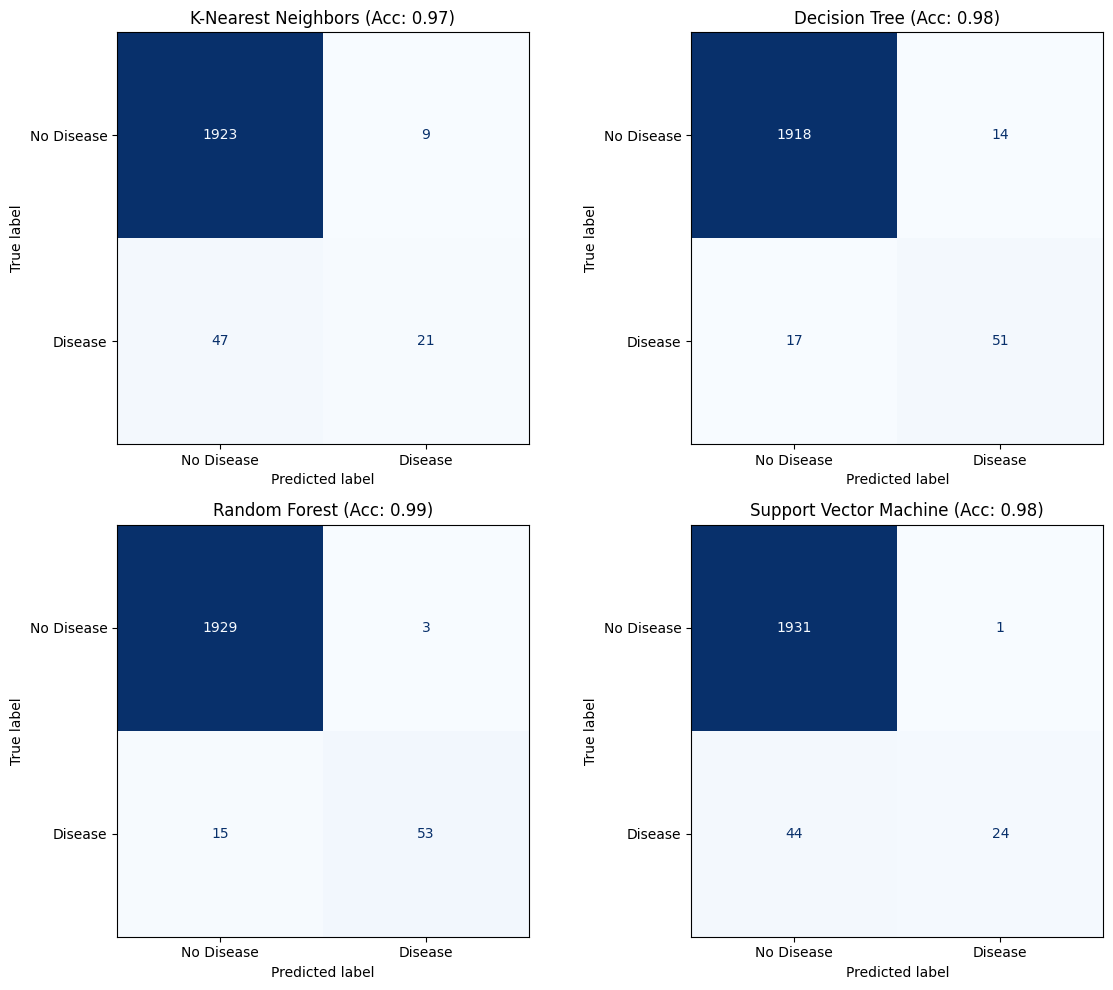

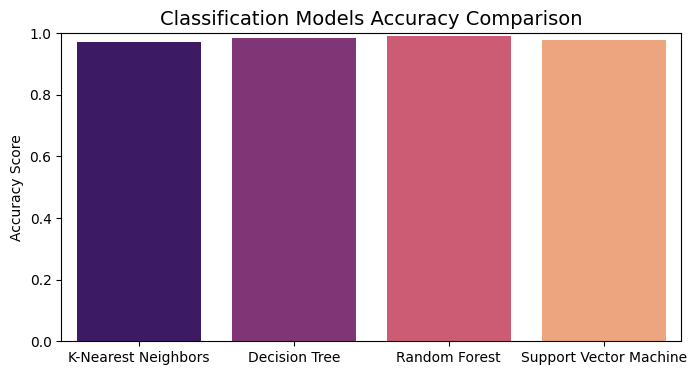

In [ ]:
print("\n✅ Data Preprocessing Complete! Training Classification Models...\n")

# Initialize models
models = {
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Support Vector Machine": SVC(random_state=42)
}

# Dictionary to store accuracy scores
accuracy_results = {}

# Train, predict, and evaluate each model
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models.items()):
    # Train
    model.fit(X_Train, Y_Train)
    # Predict
    y_pred = model.predict(X_Test)
    # Calculate Accuracy
    acc = accuracy_score(Y_Test, y_pred)
    accuracy_results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")

    # Plot Confusion Matrix
    cm = confusion_matrix(Y_Test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Disease', 'Disease'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f"{name} (Acc: {acc:.2f})")

plt.tight_layout()
plt.show()

# Plot Model Comparison
plt.figure(figsize=(8, 4))
sns.barplot(x=list(accuracy_results.keys()), y=list(accuracy_results.values()), palette='magma')
plt.title("Classification Models Accuracy Comparison", fontsize=14)
plt.ylabel("Accuracy Score")
plt.ylim(0, 1)
plt.show()

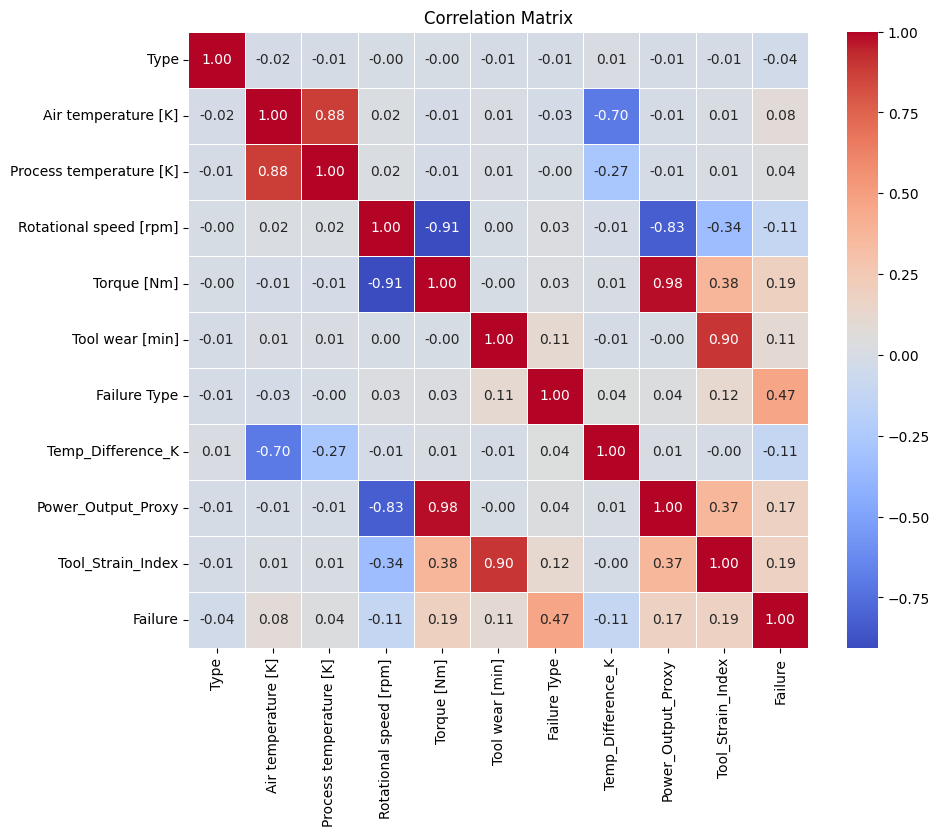

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))


sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title('Correlation Matrix')
plt.show()

#Drop selected features

In [ ]:
X = df.drop([target_column1, target_column2], axis=1)
Y = df[target_column1]

X_Train, X_Test, Y_Train, Y_Test = train_test_split(X, Y, test_size=0.2, random_state=0, stratify=Y)
print("Training Size: ", X_Train.shape)
print("Testing Size: ", X_Test.shape)

Training Size:  (8000, 9)
Testing Size:  (2000, 9)


In [ ]:
print("\nScaling numerical features...")
cols_to_scale = X_Train.select_dtypes(include=['float64', 'int64']).columns
scaler = StandardScaler()

# Fit on training data ONLY, then transform both
X_Train[cols_to_scale] = scaler.fit_transform(X_Train[cols_to_scale])
X_Test[cols_to_scale] = scaler.transform(X_Test[cols_to_scale])

display(X_Train.head())


Scaling numerical features...


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temp_Difference_K,Power_Output_Proxy,Tool_Strain_Index
8330,-0.748182,-0.601109,-0.208073,-0.172345,-0.108193,0.354069,0.891107,-0.129548,0.273740
1799,0.735570,-1.000530,-1.691299,-0.665365,0.507743,-0.208938,-0.502278,0.426218,-0.017654
7690,0.735570,0.247660,1.072895,0.282750,-0.360626,-1.632096,1.090162,-0.240893,-1.480276
3992,-0.748182,1.146356,0.870637,0.516618,-0.602962,0.322791,-0.999916,-0.488522,0.022777
1825,0.735570,-1.000530,-1.691299,1.591148,-1.239093,0.854520,-0.502278,-1.022647,0.069605


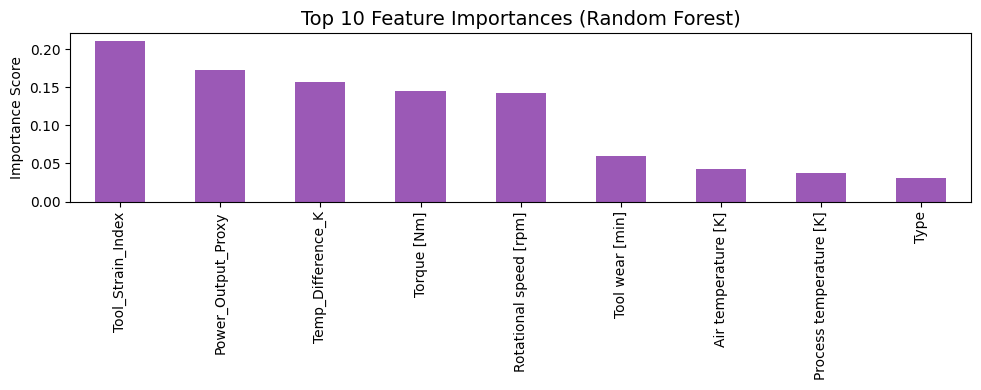

In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_Train, Y_Train)

feature_importances = pd.Series(rf.feature_importances_, index=X_Train.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 4))
feature_importances.head(10).plot(kind='bar', color='#9b59b6')
plt.title("Top 10 Feature Importances (Random Forest)", fontsize=14)
plt.ylabel("Importance Score")
plt.tight_layout()
plt.show()

In [ ]:
cols_to_drop = [
    'Type',
    'Air temperature [K]',
    'Process temperature [K]',
    'Tool wear [min]'
]

X_Train = X_Train.drop(cols_to_drop, axis=1)
X_Test = X_Test.drop(cols_to_drop, axis=1)


✅ Data Preprocessing Complete! Training Classification Models...

K-Nearest Neighbors Accuracy: 0.9790
Decision Tree Accuracy: 0.9830
Random Forest Accuracy: 0.9915
Support Vector Machine Accuracy: 0.9790


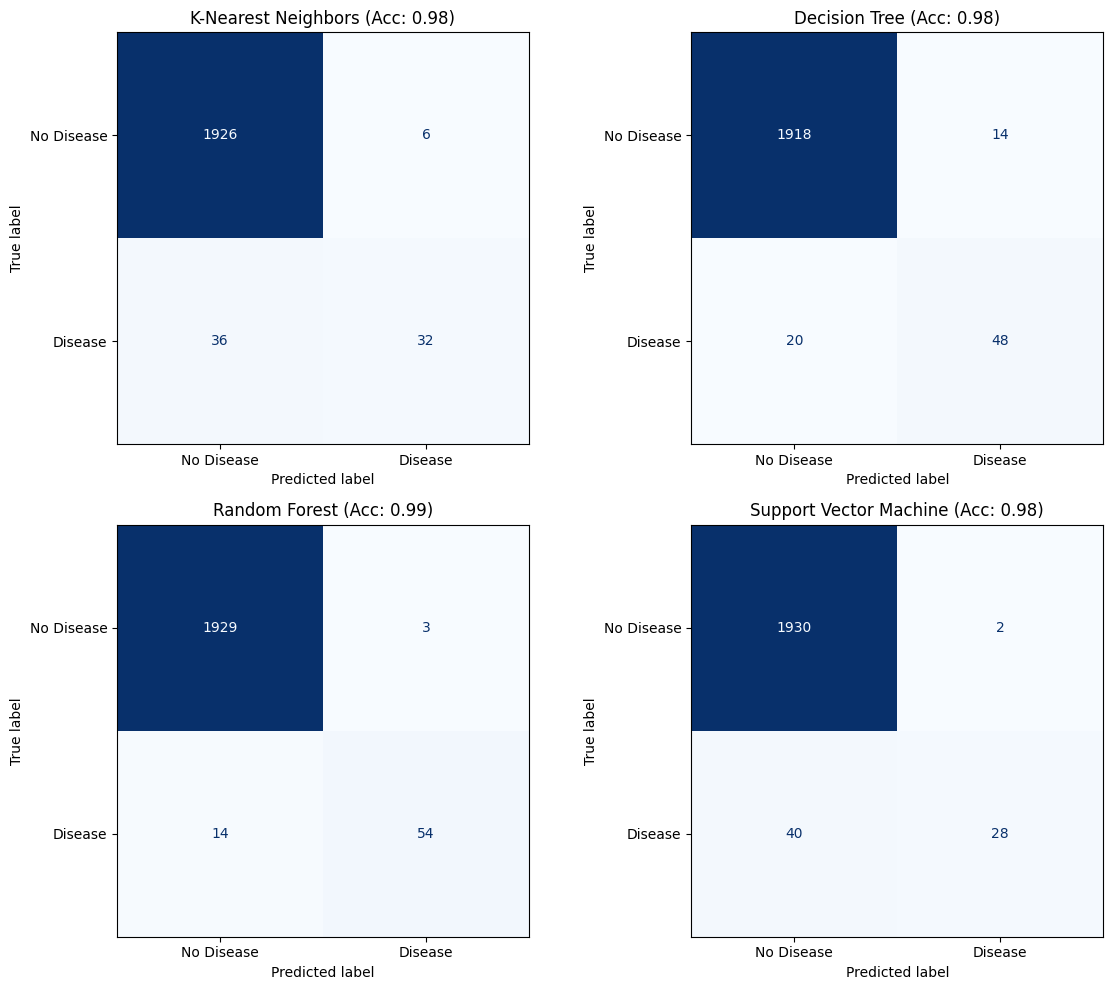

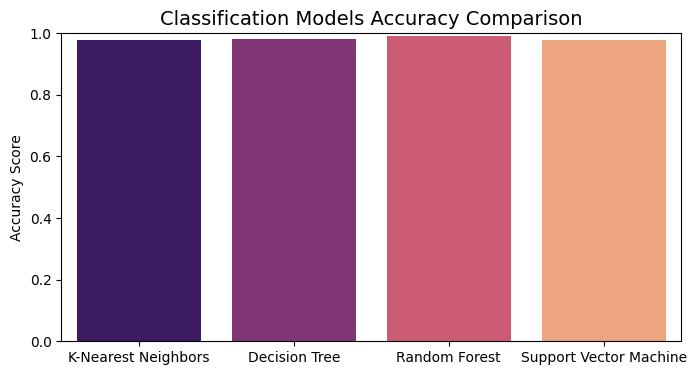

In [ ]:
print("\n✅ Data Preprocessing Complete! Training Classification Models...\n")

# Initialize models
models = {
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Support Vector Machine": SVC(random_state=42)
}

# Dictionary to store accuracy scores
accuracy_results = {}

# Train, predict, and evaluate each model
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models.items()):
    # Train
    model.fit(X_Train, Y_Train)
    # Predict
    y_pred = model.predict(X_Test)
    # Calculate Accuracy
    acc = accuracy_score(Y_Test, y_pred)
    accuracy_results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")

    # Plot Confusion Matrix
    cm = confusion_matrix(Y_Test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Disease', 'Disease'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f"{name} (Acc: {acc:.2f})")

plt.tight_layout()
plt.show()

# Plot Model Comparison
plt.figure(figsize=(8, 4))
sns.barplot(x=list(accuracy_results.keys()), y=list(accuracy_results.values()), palette='magma')
plt.title("Classification Models Accuracy Comparison", fontsize=14)
plt.ylabel("Accuracy Score")
plt.ylim(0, 1)
plt.show()

# TARGET VARIABLE NOW IS Failure Type NOT FAILURE OR NOT

In [ ]:
X = df.drop([target_column1, target_column2], axis=1)
Y = df[target_column2]

X_Train, X_Test, Y_Train, Y_Test = train_test_split(X, Y, test_size=0.2, random_state=0, stratify=Y)
print("Training Size: ", X_Train.shape)
print("Testing Size: ", X_Test.shape)

Training Size:  (8000, 9)
Testing Size:  (2000, 9)


In [ ]:
print("\nScaling numerical features...")
cols_to_scale = X_Train.select_dtypes(include=['float64', 'int64']).columns
scaler = StandardScaler()

# Fit on training data ONLY, then transform both
X_Train[cols_to_scale] = scaler.fit_transform(X_Train[cols_to_scale])
X_Test[cols_to_scale] = scaler.transform(X_Test[cols_to_scale])

display(X_Train.head())


Scaling numerical features...


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temp_Difference_K,Power_Output_Proxy,Tool_Strain_Index
8375,0.745708,-0.601348,-0.277251,-0.944740,0.834342,-1.084840,0.788817,0.670900,-0.864462
4534,-0.744590,1.196889,0.126942,0.612962,-1.196915,0.872973,-2.197948,-1.379430,0.098238
5662,-0.744590,1.096987,1.002694,0.506613,-0.593571,-1.398090,-0.704565,-0.478586,-1.302401
76,-0.744590,-0.601348,-0.748810,-0.463041,0.804175,1.530798,0.091905,0.990699,1.970750
8811,-0.744590,-1.400564,-1.018272,0.243868,-0.412568,-0.207740,1.286611,-0.341290,-0.324509



✅ Data Preprocessing Complete! Training Classification Models...

K-Nearest Neighbors Accuracy: 0.9705
Decision Tree Accuracy: 0.9860
Random Forest Accuracy: 0.9910
Support Vector Machine Accuracy: 0.9795


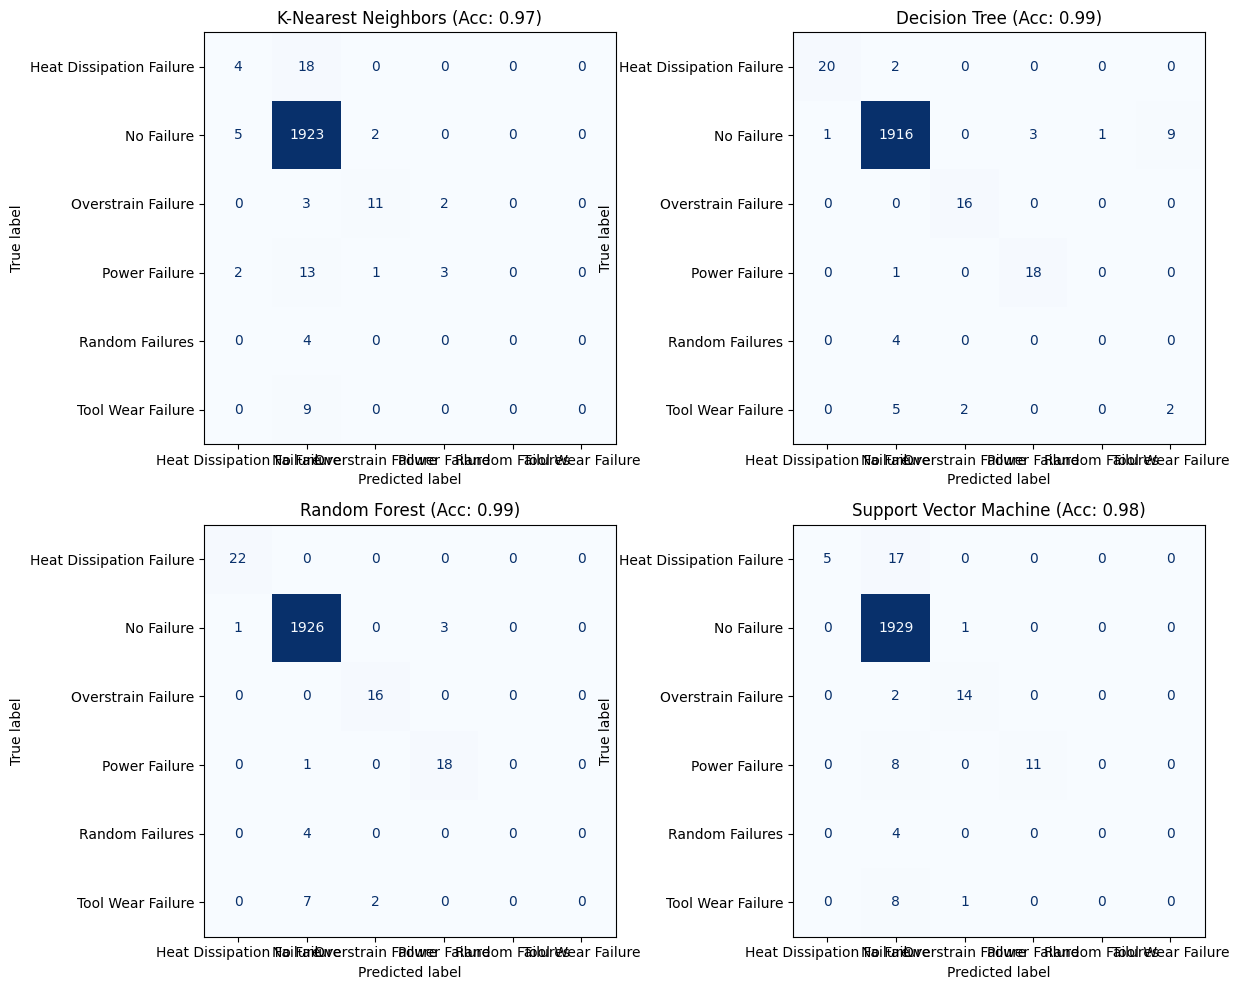

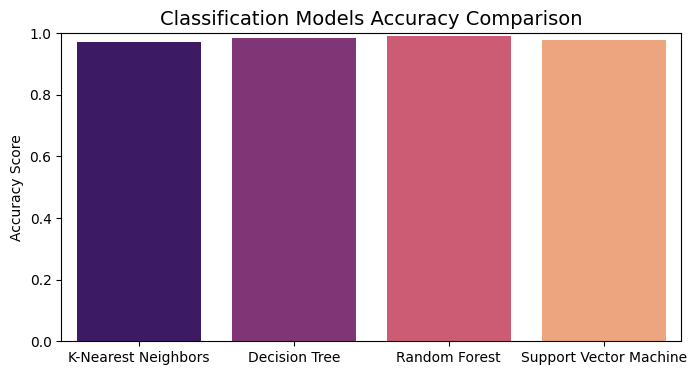

In [ ]:
print("\n✅ Data Preprocessing Complete! Training Classification Models...\n")

# Initialize models
models = {
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Support Vector Machine": SVC(random_state=42)
}

# Dictionary to store accuracy scores
accuracy_results = {}

# Train, predict, and evaluate each model
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models.items()):
    # Train
    model.fit(X_Train, Y_Train)
    # Predict
    y_pred = model.predict(X_Test)
    # Calculate Accuracy
    acc = accuracy_score(Y_Test, y_pred)
    accuracy_results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")

    # Plot Confusion Matrix
    cm = confusion_matrix(Y_Test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f"{name} (Acc: {acc:.2f})")

plt.tight_layout()
plt.show()

# Plot Model Comparison
plt.figure(figsize=(8, 4))
sns.barplot(x=list(accuracy_results.keys()), y=list(accuracy_results.values()), palette='magma')
plt.title("Classification Models Accuracy Comparison", fontsize=14)
plt.ylabel("Accuracy Score")
plt.ylim(0, 1)
plt.show()